# Regressão - Previsão da Nota Final de Alunos

## 1. Definição do problema

Identificar cedo os alunos que podem terminar o ano com nota baixa permite que a escola ofereça reforço, acompanhamento ou converse com a família antes que seja tarde. Para isso, é útil saber se dá para estimar a nota final a partir de informações que a escola já tem, como as notas dos bimestres anteriores, faltas e dados sobre a vida do aluno.

**Pergunta principal:** É possível prever a nota final de um aluno de matemática a partir das notas anteriores e de informações sobre sua rotina e família?

**Tipo de problema:** Regressão, pois a variável alvo é um número (nota de 0 a 20).

## 2. Apresentação da base de dados

- **Nome:** Student Performance (arquivo `student-mat.csv`, disciplina de matemática)
- **Origem:** dados coletados em duas escolas públicas de Portugal (2005-2006) por questionários e registros escolares, publicados no UCI Machine Learning Repository: https://archive.ics.uci.edu/dataset/320/student+performance
- **Registros:** 395 alunos
- **Colunas:** 33 (32 variáveis de entrada e 1 variável alvo)

Principais colunas:

| Coluna | Significado |
|---|---|
| school | escola (GP ou MS) |
| sex, age | sexo e idade do aluno |
| Medu, Fedu | escolaridade da mãe e do pai (0 = nenhuma até 4 = ensino superior) |
| studytime | tempo de estudo semanal (1 = menos de 2h até 4 = mais de 10h) |
| failures | número de reprovações anteriores |
| schoolsup, famsup | se recebe apoio extra da escola / da família |
| higher | se quer fazer ensino superior |
| internet | se tem internet em casa |
| goout | quanto sai com os amigos (1 = muito pouco até 5 = muito) |
| Dalc, Walc | consumo de álcool durante a semana / no fim de semana (1 a 5) |
| absences | número de faltas |
| G1, G2 | notas do 1º e do 2º período (0 a 20) |
| G3 | **variável alvo**: nota final (0 a 20) |

As outras colunas trazem informações sobre família, tempo livre, saúde e atividades extracurriculares.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# carregando os dados (o arquivo usa ; como separador)
df = pd.read_csv('../dados/student-mat.csv', sep=';')

print('Linhas:', df.shape[0])
print('Colunas:', df.shape[1])

Linhas: 395
Colunas: 33


## 3. Análise exploratória dos dados

In [3]:
# primeiras linhas
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [4]:
# tipos de dados
df.dtypes

school          str
sex             str
age           int64
address         str
famsize         str
Pstatus         str
Medu          int64
Fedu          int64
Mjob            str
Fjob            str
reason          str
guardian        str
traveltime    int64
studytime     int64
failures      int64
schoolsup       str
famsup          str
paid            str
activities      str
nursery         str
higher          str
internet        str
romantic        str
famrel        int64
freetime      int64
goout         int64
Dalc          int64
Walc          int64
health        int64
absences      int64
G1            int64
G2            int64
G3            int64
dtype: object

In [5]:
# valores ausentes
print('Total de valores ausentes:', df.isnull().sum().sum())

Total de valores ausentes: 0


In [6]:
# registros duplicados
print('Duplicados:', df.duplicated().sum())

Duplicados: 0


In [7]:
# estatisticas basicas
df.describe().round(2)

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00
mean,16.70,2.75,2.52,1.45,2.04,0.33,3.94,3.24,3.11,1.48,2.29,3.55,5.71,10.91,10.71,10.42
std,1.28,1.09,1.09,0.70,0.84,0.74,0.90,1.00,1.11,0.89,1.29,1.39,8.00,3.32,3.76,4.58
min,15.00,0.00,0.00,1.00,1.00,0.00,1.00,1.00,1.00,1.00,1.00,1.00,0.00,3.00,0.00,0.00
25%,16.00,2.00,2.00,1.00,1.00,0.00,4.00,3.00,2.00,1.00,1.00,3.00,0.00,8.00,9.00,8.00
50%,17.00,3.00,2.00,1.00,2.00,0.00,4.00,3.00,3.00,1.00,2.00,4.00,4.00,11.00,11.00,11.00
75%,18.00,4.00,3.00,2.00,2.00,0.00,5.00,4.00,4.00,2.00,3.00,5.00,8.00,13.00,13.00,14.00
max,22.00,4.00,4.00,4.00,4.00,3.00,5.00,5.00,5.00,5.00,5.00,5.00,75.00,19.00,19.00,20.00


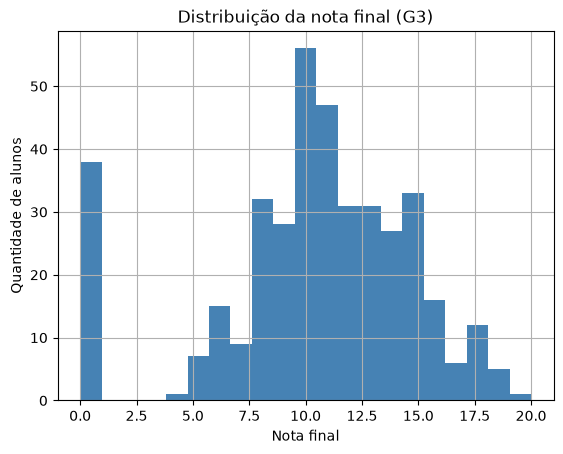

In [8]:
# distribuicao da nota final
df['G3'].hist(bins=21, color='steelblue')
plt.title('Distribuição da nota final (G3)')
plt.xlabel('Nota final')
plt.ylabel('Quantidade de alunos')
plt.show()

In [9]:
# alunos com nota final zero
zerados = df[df['G3'] == 0]
print('Alunos com nota final 0:', len(zerados))
print()
print(zerados[['G1', 'G2', 'G3', 'absences']].describe().round(1))

Alunos com nota final 0: 38

         G1    G2    G3  absences
count  38.0  38.0  38.0      38.0
mean    7.5   4.7   0.0       0.0
std     1.8   3.7   0.0       0.0
min     4.0   0.0   0.0       0.0
25%     6.0   0.0   0.0       0.0
50%     7.0   5.0   0.0       0.0
75%     9.0   8.0   0.0       0.0
max    12.0  10.0   0.0       0.0


O histograma mostra um grupo de alunos com nota final 0, separado do resto. Esses 38 alunos tiveram notas no 1º período (entre 4 e 12) e têm **zero faltas**, o que indica que eles provavelmente abandonaram a disciplina ou não fizeram a prova final, e não que tiraram zero de verdade.

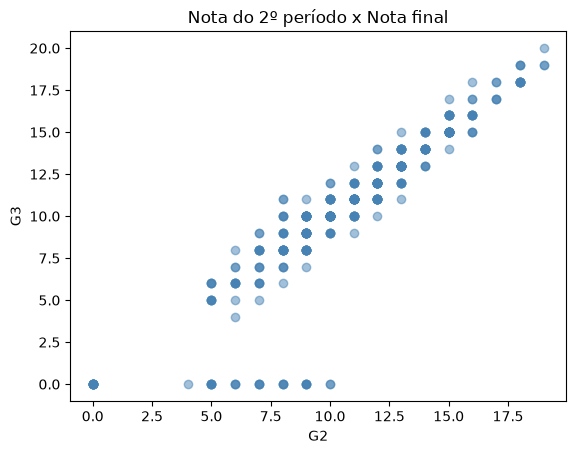

In [10]:
# relacao entre a nota do 2o periodo e a nota final
plt.scatter(df['G2'], df['G3'], alpha=0.5, color='steelblue')
plt.title('Nota do 2º período x Nota final')
plt.xlabel('G2')
plt.ylabel('G3')
plt.show()

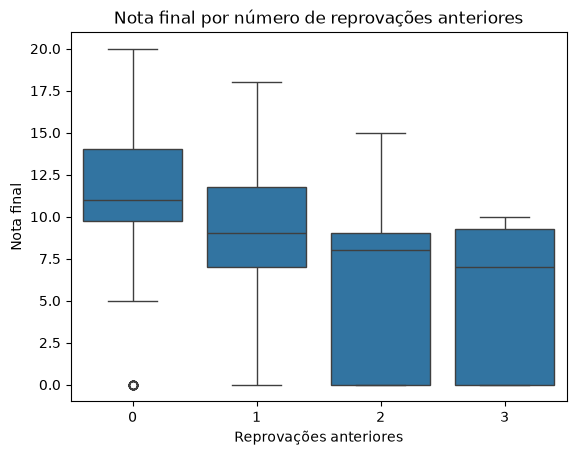

In [11]:
# nota final por numero de reprovacoes
sns.boxplot(data=df, x='failures', y='G3')
plt.title('Nota final por número de reprovações anteriores')
plt.xlabel('Reprovações anteriores')
plt.ylabel('Nota final')
plt.show()

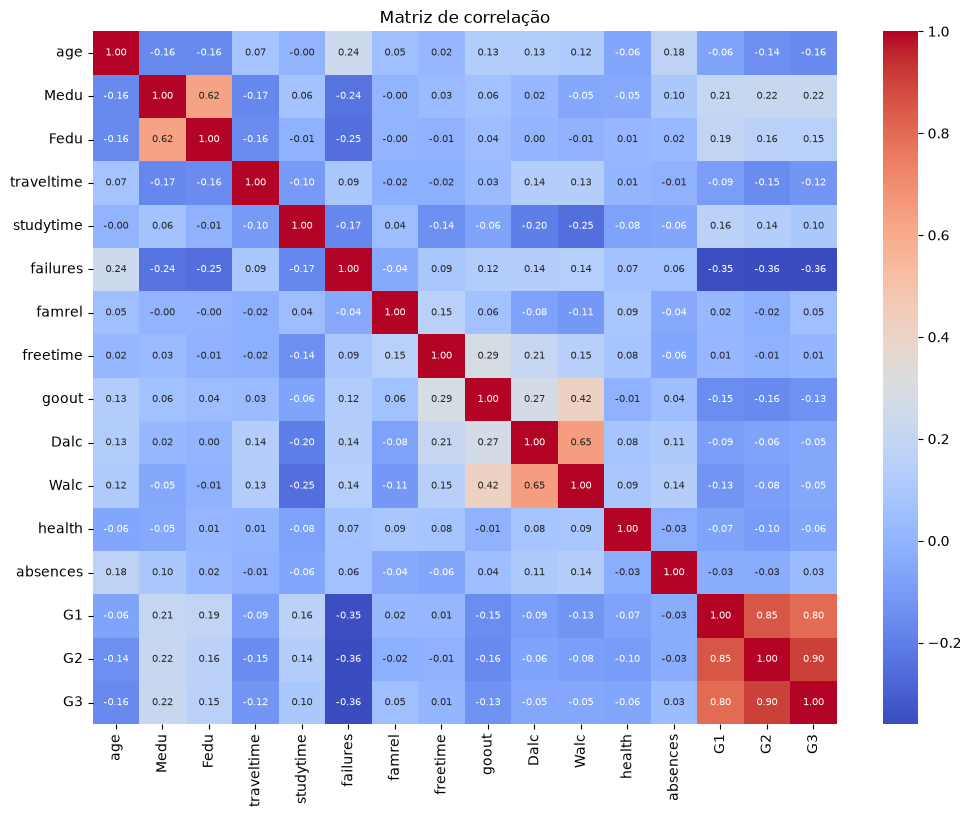

In [12]:
# matriz de correlacao das colunas numericas
plt.figure(figsize=(12, 9))
sns.heatmap(df.select_dtypes('number').corr(), annot=True, fmt='.2f', cmap='coolwarm', annot_kws={'size': 7})
plt.title('Matriz de correlação')
plt.show()

**O que a análise mostrou:**

- A base tem 395 alunos, 33 colunas (16 numéricas e 17 de texto), sem valores ausentes e sem duplicados.
- A nota final média é 10,4 (de 0 a 20). Existem 38 alunos com nota final 0 que provavelmente não fizeram a prova final, e isso será tratado na preparação.
- As notas dos períodos anteriores têm relação muito forte com a nota final: correlação de 0,90 para G2 e 0,80 para G1. O gráfico de dispersão mostra os pontos quase em linha reta.
- O **número de reprovações anteriores** é a variável com a correlação negativa mais forte (-0,36): a nota média cai de 11,3 para quem nunca reprovou para 5,7 para quem reprovou 3 vezes.
- A escolaridade da mãe (0,22) e do pai (0,15) têm uma relação positiva fraca com a nota. Sair muito com os amigos (-0,13) e a idade (-0,16) têm relação negativa fraca.